# E-Means 검증 — LUMI 데이터에서 k-means 계열 4종 비교

**목적**
1. Meta FAIR 의 E-Means(공식 구현 `faiss.contrib.e_means`, Faiss 1.16.0)가 논문 주장대로 **적은 epoch·짧은 시간에 k-means 품질**에 도달하는지, **우리 데이터**로 직접 확인한다.
2. 우리가 처음 떠올린 **단순 이동평균(EMA) k-means**(고정 α)와, 기존 미니배치 k-means(Sculley 2010), 표준 Lloyd k-means 를 같은 조건에서 비교한다.
3. LUMI 에서 쓸 곳: **(B) 합성 데이터의 커버리지·불균형·중복 분석**, **(C) 깜빡임 패치 군집 → ROI 후보**.

### 원문 확인 (2026-11-11)
| 항목 | 내용 | 등급 |
|---|---|---|
| 논문 | Bessa, Mazaré, Szilvasy, Touvron, Picard, Douze, Jégou, **"e-means: outperforming k-means (in one-tenth the epochs)"**, arXiv:2611.09501, v1 2026-11-06 (FAIR at Meta) | 원문 |
| 핵심 주장 | 초록: "it beats the loss of Lloyd k-means at 25 epochs in **1.4 to 2.6 epochs**, which translates to **10-45× GPU wall-clock speedups**". 단 표 4의 기준은 Flash-KMeans@25, GPU(H100), 데이터 1M~1B·96~1024차원 | 원문 |
| 방법 | 질량 N_j·합 S_j 의 EMA(식 2) + α 코사인 감쇠(식 5) + 5배치마다 죽은 군집을 큰 군집 분할로 복구(τ=0.1) + 마지막 epoch 평균으로 마무리 + **배치 크기 B·초기 α₀ 를 n·k·T 로 정하는 스케일링 법칙**(식 6·7) | 원문 |
| 평가 방식 | hold-out test MSE, Lloyd@25 대비 상대 MSE, MSE 대 epoch(로그), MSE 대 wall-clock, 시드 분포 → 이 노트북도 같은 방식 | 원문 |
| 공식 구현 | Faiss 1.16.0 `faiss/contrib/e_means/` (`NumpyEmeans`, GPU 는 `Emeans`), MIT | 원문 |
| SAM2 와의 관계 | 논문·README·웹사이트 어디에도 없음 | 없음 |
| 우리 데이터에 대한 주의 | 스케일링 법칙은 DEEP(96차원) 하나로 적합했고, 저자 스스로 "저차원에서는 최적이 아니다"(부록 D.2). 우리 패치 특징은 26차원 | 원문 |

### 선행연구: 이동평균 계열 중심점 갱신은 오래된 아이디어다 (원문 확인)
| 문헌 | 갱신식 | E-Means 와의 차이 (E-Means 원문의 주장) |
|---|---|---|
| MacQueen 1967 | 점 하나씩, 학습률 1/(개수) — 누적 평균 | |
| Sculley 2010 (WWW) | 배치, 중심점별 η = 1/v[c] — 누적 평균 | "none of them supplies a way to adapt the batch size and the step" |
| VQ-VAE 2017 부록 A.1 | N·m 의 EMA, γ = 0.99 고정 — **우리 '단순 EMA' 와 같은 계열** | "never compared to Lloyd's full-batch k-means … EMA decay treated as an inherited constant" |
| **E-Means 2026** | EMA + α·B 자동 결정 + 코사인 감쇠 + 죽은 군집 복구 | 위 둘을 체계화하고 Lloyd 와 정면 비교 |

**안전**: 이 노트북은 영상을 재생하지 않는다. 미리 뽑아 둔 숫자 특징(`data/emeans/`)만 읽는다.
**선행 조건**: `python scripts/emeans_features.py` (한 번, 약 40분) → `data/emeans/` 생성.
**결과 저장**: 그래프는 한 장씩 `checks/emeans/` 와 발표용 사본 `C:\dev\lumi-vision\reports\발표_그래프\emeans\` 에 저장된다.

| 비교 대상 | 중심점 갱신 | 출처 |
|---|---|---|
| Lloyd k-means | 매 epoch 전체 평균으로 교체 | `faiss.Kmeans` |
| 미니배치 k-means | 배치마다 중심점별 학습률 1/n (누적 평균) | Sculley 2010, `sklearn.MiniBatchKMeans` (기본 설정) |
| **단순 EMA k-means (우리 착안)** | 배치마다 c ← (1−α)c + α·(배치 평균), α 고정 | 이 노트북에서 직접 구현 |
| **E-Means** | EMA + 배치 크기·α 자동 결정(scaling law) + cosine 감쇠 + 죽은 군집 복구 | `faiss.contrib.e_means.NumpyEmeans` |


In [1]:
# 0. 환경
import json, time, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import faiss, sklearn
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score
from faiss.contrib.e_means import NumpyEmeans

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA, OUT = ROOT / 'data' / 'emeans', ROOT / 'checks' / 'emeans'
PRES = ROOT.parent / 'reports' / '발표_그래프' / 'emeans'      # 발표용 사본
OUT.mkdir(parents=True, exist_ok=True); PRES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110})
def save(fig, name):
    for d in (OUT, PRES):
        fig.savefig(d / f'{name}.png', dpi=200, bbox_inches='tight')
pct = FuncFormatter(lambda v, _: f'{v:+.0f}%' if abs(v) >= 1 or v == 0 else f'{v:+.1f}%')
print('python', platform.python_version(), '| faiss', faiss.__version__, '| sklearn', sklearn.__version__)
print('데이터 폴더:', DATA, '있음' if DATA.exists() else '없음 → scripts/emeans_features.py 먼저')

python 3.14.7 | faiss 1.16.0 | sklearn 1.9.1
데이터 폴더: C:\dev\lumi-vision\lumi-lab-ryujungho2-collab\data\emeans 있음


## 1. 설정 — 여기 값을 바꿔 가며 직접 실험해 보세요
- `QUICK = True` 이면 패치를 30만 개만 써서 몇 분 안에 끝난다(전체는 약 30분).
- `K`: 군집 수, `BUDGETS`: epoch 예산, `SEEDS`: 반복 시드(안정성 측정용), `ALPHA`: 단순 EMA 의 고정 α

In [2]:
QUICK = False         # True 로 바꾸면 패치 30만 개로 몇 분 안에 끝남
K = 64
BUDGETS = [1, 2, 3, 5, 10, 25]
SEEDS = [0, 1, 2]
BATCH = 4096          # 미니배치·단순 EMA 의 배치 크기 (E-Means 는 자기 규칙으로 정함)
ALPHA = 0.05          # 단순 EMA 의 고정 α
N_QUICK = 300_000

## 2. 데이터
- **패치 특징** (각 16×16 패치의 휘도 시간 신호): `[평균 밝기, 밝기 범위, |FFT| 0.5~12 Hz 24칸]`, 모두 ÷200 cd/m². 26차원.
- 출처: 768×432 오라클 352클립 + GAN 평가 샘플 1,440클립(실험 15개 × 96) → 패치 약 232만 개.
- 같은 클립의 패치가 학습·시험에 섞이지 않도록 **클립 단위로 8:2 분할**한다.

In [3]:
X = np.load(DATA / 'patch_feats.npy').astype('float32')
pm = np.load(DATA / 'patch_meta.npz')
info = json.loads((DATA / 'info.json').read_text(encoding='utf-8'))
clip_meta = pd.read_csv(DATA / 'clip_meta.csv')
rng = np.random.default_rng(0)
clips = np.unique(pm['clip']); test_clips = set(rng.choice(clips, len(clips) // 5, replace=False))
is_test = np.isin(pm['clip'], list(test_clips))
Xtr, Xte = X[~is_test], X[is_test]
if QUICK:
    Xtr = Xtr[rng.choice(len(Xtr), min(N_QUICK, len(Xtr)), replace=False)]
    Xte = Xte[rng.choice(len(Xte), min(N_QUICK // 4, len(Xte)), replace=False)]
print(f'전체 패치 {len(X):,} (클립 {len(clips)}) → 학습 {len(Xtr):,} / 시험 {len(Xte):,}, 차원 {X.shape[1]}')
print('위험 패치 비율:', round(float(pm['hazard'].mean()), 4))

전체 패치 2,322,432 (클립 1792) → 학습 1,858,464 / 시험 463,968, 차원 26
위험 패치 비율: 0.2976


## 3. 알고리즘 4종 (같은 초기 중심점에서 출발)

In [4]:
def test_mse(C, Xq):
    idx = faiss.IndexFlatL2(C.shape[1]); idx.add(np.ascontiguousarray(C, dtype='float32'))
    D, I = idx.search(Xq, 1)
    return float(D.mean()), I[:, 0]

def init_centroids(seed):
    return Xtr[np.random.RandomState(seed).permutation(len(Xtr))[:K]].copy()

def run_lloyd(epochs, seed):
    km = faiss.Kmeans(Xtr.shape[1], K, niter=epochs, seed=seed, max_points_per_centroid=10**9)
    km.train(Xtr, init_centroids=init_centroids(seed)); return km.centroids

def run_minibatch(epochs, seed):
    mb = MiniBatchKMeans(K, init=init_centroids(seed), n_init=1, batch_size=BATCH, max_iter=epochs,
                         tol=0.0, max_no_improvement=None, random_state=seed)   # 죽은 군집 재배치 등은 sklearn 기본값
    mb.fit(Xtr); return mb.cluster_centers_.astype('float32')

def run_simple_ema(epochs, seed, alpha=ALPHA):
    C = init_centroids(seed); r = np.random.RandomState(seed)
    idx = faiss.IndexFlatL2(C.shape[1])
    for _ in range(epochs):
        order = r.permutation(len(Xtr))
        for b in range(0, len(Xtr), BATCH):
            xb = Xtr[order[b:b + BATCH]]
            idx.reset(); idx.add(C); _, I = idx.search(xb, 1); I = I[:, 0]
            cnt = np.bincount(I, minlength=K)
            s = np.zeros_like(C); np.add.at(s, I, xb)
            hit = cnt > 0
            C[hit] = (1 - alpha) * C[hit] + alpha * (s[hit] / cnt[hit, None])
    return C

def run_emeans(epochs, seed, alpha0=None):
    em = NumpyEmeans(Xtr.shape[1], K, nepochs=epochs, seed=seed, alpha0=alpha0)
    em.train(Xtr, init_centroids=init_centroids(seed)); return em.centroids, em.recipe

ALGOS = {'Lloyd k-means': run_lloyd, '미니배치 (Sculley 2010)': run_minibatch,
         '단순 EMA (우리 착안)': run_simple_ema, 'E-Means': lambda e, s: run_emeans(e, s)[0]}
COL = {'Lloyd k-means': 'C1', '미니배치 (Sculley 2010)': 'C3', '단순 EMA (우리 착안)': 'C2', 'E-Means': 'C0'}
_, recipe = run_emeans(1, 0)
print('E-Means 가 자동으로 정한 설정:', {k: recipe[k] for k in recipe if k in ('batch_size', 'alpha0', 'batch_law', 'batch_law_reason')})

E-Means 가 자동으로 정한 설정: {'batch_law': 'throughput', 'batch_law_reason': 'd > 16', 'batch_size': 16384, 'alpha0': 1.0}


## 4. 실험 A — 수렴·속도·안정성
각 (알고리즘, epoch 예산, 시드)마다 **시험 MSE**(학습에 안 쓴 클립의 패치를 가장 가까운 중심점에 붙였을 때의 평균 제곱거리, 낮을수록 좋음)와 **실행 시간**(CPU)을 잰다.
논문과 같이 **Lloyd 25 epoch 대비 상대 MSE** 로 그린다.

In [5]:
rows, final_C = [], {}
for name, fn in ALGOS.items():
    for e in BUDGETS:
        for s in SEEDS:
            t0 = time.perf_counter(); Cn = fn(e, s); sec = time.perf_counter() - t0
            mse, labels = test_mse(Cn, Xte)
            rows.append({'알고리즘': name, 'epoch': e, 'seed': s, '시험 MSE': mse, '시간(초)': sec})
            if e == max(BUDGETS): final_C[(name, s)] = (Cn, labels)
    print(f'{name}: 끝 ({sum(r["시간(초)"] for r in rows if r["알고리즘"] == name):.1f}초)')
res = pd.DataFrame(rows)
ref = res[(res['알고리즘'] == 'Lloyd k-means') & (res['epoch'] == max(BUDGETS))]['시험 MSE'].mean()
res['상대 MSE(%)'] = 100 * (res['시험 MSE'] - ref) / ref
res.to_csv(OUT / 'A_convergence.csv', index=False, encoding='utf-8-sig')
res.groupby(['epoch', '알고리즘'])[['상대 MSE(%)', '시간(초)']].mean().unstack(1).round(2)

Lloyd k-means: 끝 (24.3초)


미니배치 (Sculley 2010): 끝 (759.8초)


단순 EMA (우리 착안): 끝 (88.4초)


E-Means: 끝 (106.9초)


상대 MSE(%)                                                    시간(초)  \
알고리즘    E-Means Lloyd k-means 단순 EMA (우리 착안) 미니배치 (Sculley 2010) E-Means   
epoch                                                                      
1         -1.26         30.81           0.27                6.12    0.84   
2         -2.59         19.41          -1.71                5.45    1.60   
3         -2.05         14.20          -2.88                5.11    2.34   
5         -3.26          9.08          -4.18                4.73    3.87   
10        -3.38          3.98          -4.90                4.27    7.72   
25        -3.70         -0.00          -5.11                3.75   19.26   

                                                        
알고리즘  Lloyd k-means 단순 EMA (우리 착안) 미니배치 (Sculley 2010)  
epoch                                                   
1              0.28           0.67                5.58  
2              0.43           1.30               11.09  
3              0.59           1.94               16.91  
5              0.92           3.23               27.55  
10             1.73           6.38               54.87  
25             4.14          15.95              137.28

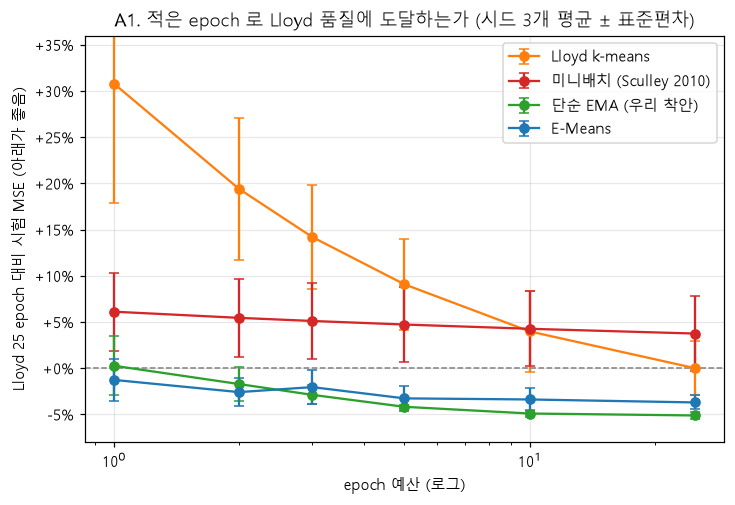

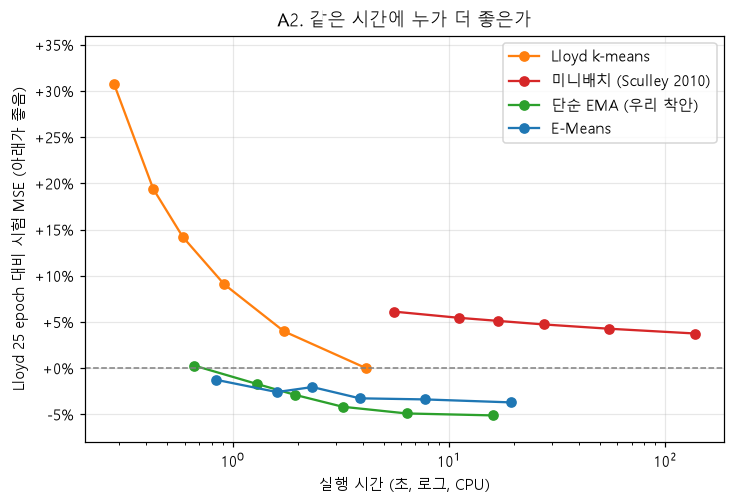

In [6]:
# 그래프 A1 (epoch 대비) · A2 (시간 대비)
def style(ax, xlabel):
    ax.axhline(0, ls='--', c='gray', lw=1); ax.set_xscale('log'); ax.set_xlabel(xlabel)
    ax.set_ylabel(f'Lloyd {max(BUDGETS)} epoch 대비 시험 MSE (아래가 좋음)'); ax.yaxis.set_major_formatter(pct)
    ax.set_ylim(-8, 36); ax.grid(alpha=.3); ax.legend()
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for name in ALGOS:
    m = res[res['알고리즘'] == name].groupby('epoch')['상대 MSE(%)']
    ax.errorbar(m.mean().index, m.mean(), yerr=m.std(), marker='o', capsize=3, label=name, color=COL[name])
style(ax, 'epoch 예산 (로그)'); ax.set_title('A1. 적은 epoch 로 Lloyd 품질에 도달하는가 (시드 3개 평균 ± 표준편차)')
save(fig, 'A1_epoch'); plt.show()
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for name in ALGOS:
    m = res[res['알고리즘'] == name].groupby('epoch')[['상대 MSE(%)', '시간(초)']].mean()
    ax.plot(m['시간(초)'], m['상대 MSE(%)'], marker='o', label=name, color=COL[name])
style(ax, '실행 시간 (초, 로그, CPU)'); ax.set_title('A2. 같은 시간에 누가 더 좋은가')
save(fig, 'A2_time'); plt.show()

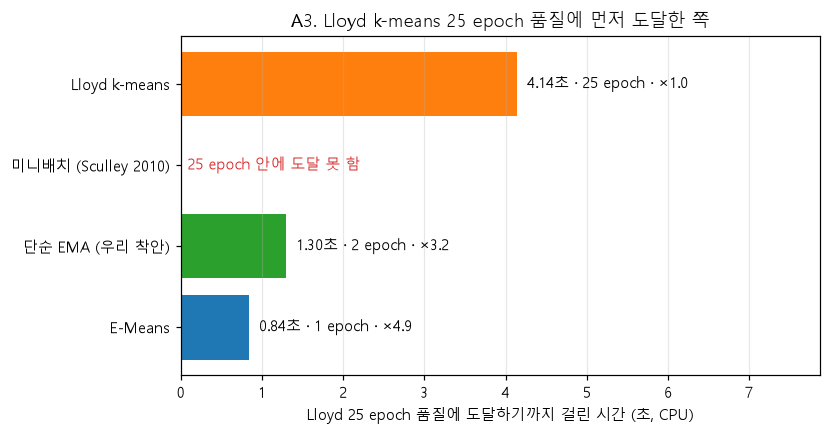

,도달 epoch,도달 시간(초),Lloyd 대비 속도(배)
알고리즘,,,
Lloyd k-means,25.0,4.141534,1.0
미니배치 (Sculley 2010),NaN,NaN,NaN
단순 EMA (우리 착안),2.0,1.298236,3.2
E-Means,1.0,0.841307,4.9


In [7]:
# 그래프 A3: Lloyd 25 epoch 품질에 처음 도달(같거나 더 좋음)한 epoch 와 그때까지의 시간
m = res.groupby(['알고리즘', 'epoch'])[['상대 MSE(%)', '시간(초)']].mean().reset_index()
rows = []
for name in ALGOS:
    g = m[(m['알고리즘'] == name) & (m['상대 MSE(%)'] <= 0)].sort_values('epoch')
    rows.append({'알고리즘': name, '도달 epoch': int(g['epoch'].iloc[0]) if len(g) else np.nan,
                 '도달 시간(초)': float(g['시간(초)'].iloc[0]) if len(g) else np.nan})
reach = pd.DataFrame(rows).set_index('알고리즘')
reach['Lloyd 대비 속도(배)'] = (reach.loc['Lloyd k-means', '도달 시간(초)'] / reach['도달 시간(초)']).round(1)
reach.to_csv(OUT / 'A3_reach.csv', encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(7.5, 4.0))
names = list(ALGOS); vmax = reach['도달 시간(초)'].max()
for k, n in enumerate(names):
    v = reach.loc[n, '도달 시간(초)']
    if np.isnan(v):
        ax.text(0.02 * vmax, k, f'{max(BUDGETS)} epoch 안에 도달 못 함', va='center', color='C3')
    else:
        ax.barh(k, v, color=COL[n])
        ax.text(v, k, f'  {v:.2f}초 · {int(reach.loc[n, "도달 epoch"])} epoch · ×{reach.loc[n, "Lloyd 대비 속도(배)"]:.1f}', va='center')
ax.set_yticks(range(len(names)), names); ax.invert_yaxis(); ax.set_xlim(0, vmax * 1.9)
ax.set_xlabel(f'Lloyd {max(BUDGETS)} epoch 품질에 도달하기까지 걸린 시간 (초, CPU)'); ax.grid(alpha=.3, axis='x')
ax.set_title(f'A3. Lloyd k-means {max(BUDGETS)} epoch 품질에 먼저 도달한 쪽')
save(fig, 'A3_reach'); plt.show(); reach

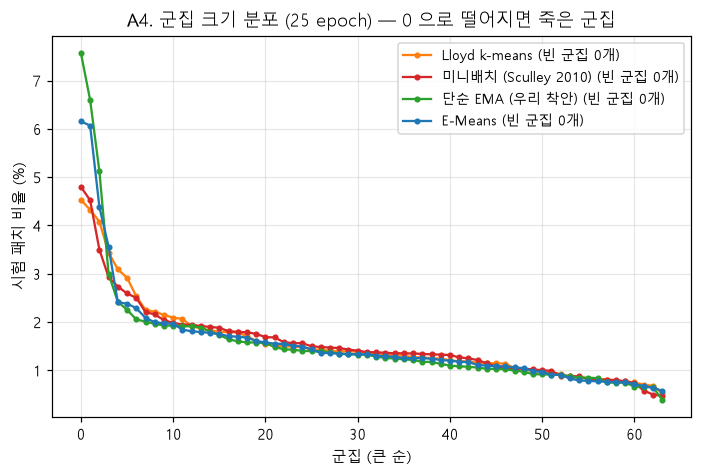

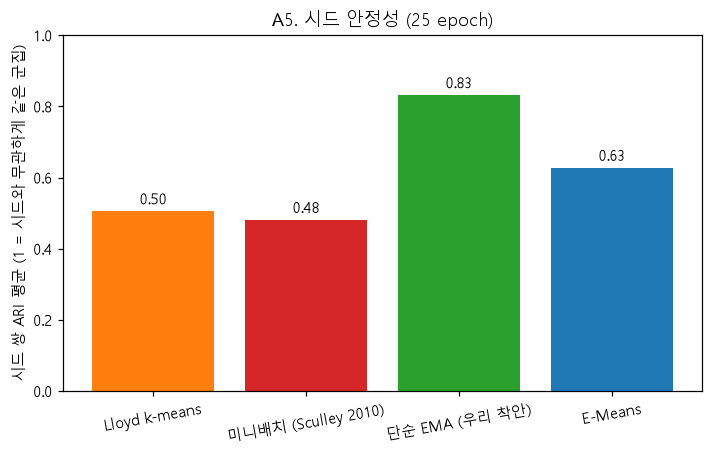

In [8]:
# 그래프 A4 (죽은 군집) · A5 (시드 안정성)
fig, ax = plt.subplots(figsize=(7.5, 4.5)); stab = {}
for name in ALGOS:
    Cn, labels = final_C[(name, SEEDS[0])]
    sizes = np.sort(np.bincount(labels, minlength=K))[::-1] / len(labels) * 100
    ax.plot(sizes, marker='.', label=f'{name} (빈 군집 {int((sizes == 0).sum())}개)', color=COL[name])
    labs = [final_C[(name, s_)][1] for s_ in SEEDS]
    stab[name] = np.mean([adjusted_rand_score(labs[a], labs[b]) for a in range(len(labs)) for b in range(a + 1, len(labs))])
ax.set_xlabel('군집 (큰 순)'); ax.set_ylabel('시험 패치 비율 (%)'); ax.grid(alpha=.3); ax.legend(fontsize=9)
ax.set_title(f'A4. 군집 크기 분포 ({max(BUDGETS)} epoch) — 0 으로 떨어지면 죽은 군집')
save(fig, 'A4_cluster_sizes'); plt.show()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(range(len(stab)), list(stab.values()), color=[COL[n] for n in stab]); ax.set_ylim(0, 1)
ax.set_xticks(range(len(stab)), list(stab), rotation=10)
for k, v in enumerate(stab.values()): ax.text(k, v + .02, f'{v:.2f}', ha='center')
ax.set_ylabel('시드 쌍 ARI 평균 (1 = 시드와 무관하게 같은 군집)'); ax.set_title(f'A5. 시드 안정성 ({max(BUDGETS)} epoch)')
save(fig, 'A5_seed_stability'); plt.show()

### A6. α 민감도 — '단순 EMA 가 E-Means 보다 좋다'가 α 운인가?
단순 EMA 는 α 를 사람이 정해야 한다(위에서는 0.05). E-Means 는 α₀ 를 법칙으로 정한다(위 셀 출력의 `alpha0`).
α 를 바꿔 가며 단순 EMA 와 E-Means(α₀ 직접 지정)를 3 epoch·25 epoch 에서 비교한다.

3 epoch 끝


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


C:\Users\thefi\AppData\Local\Temp\ipykernel_32980\3554278473.py:19: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Malgun Gothic.
  fig.savefig(d / f'{name}.png', dpi=200, bbox_inches='tight')
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (16 outputs left out)

C:\dev\lumi-vision\lumi-lab-ryujungho2-collab\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


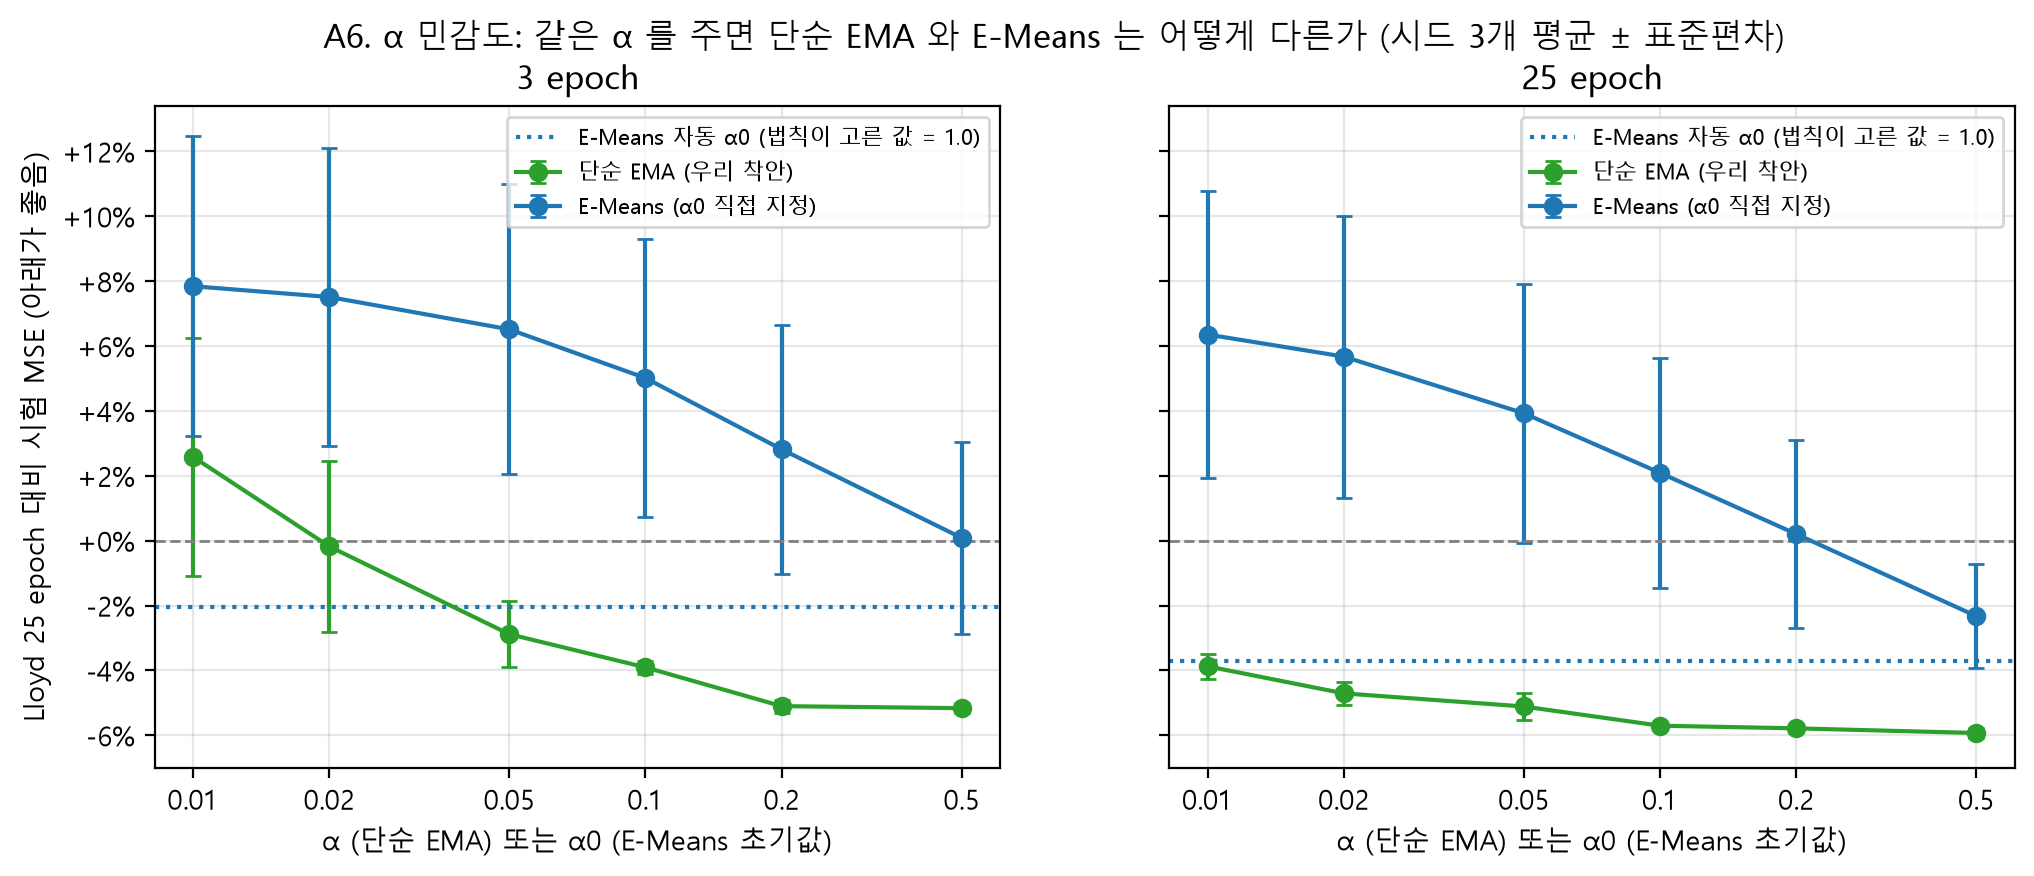

방법          E-Means (α₀ 지정)  단순 EMA
epoch α                            
3     0.01             7.84    2.59
      0.02             7.51   -0.18
      0.05             6.52   -2.88
      0.10             5.01   -3.91
      0.20             2.82   -5.10
      0.50             0.09   -5.16
25    0.01             6.36   -3.87
      0.02             5.68   -4.71
      0.05             3.93   -5.11
      0.10             2.09   -5.70
      0.20             0.21   -5.79
      0.50            -2.32   -5.93

In [9]:
ALPHAS = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
rows = []
for e in (3, 25):
    for a in ALPHAS:
        for s_ in SEEDS:
            rows.append({'방법': '단순 EMA', 'α': a, 'epoch': e,
                         '상대 MSE(%)': 100 * (test_mse(run_simple_ema(e, s_, a), Xte)[0] - ref) / ref})
            rows.append({'방법': 'E-Means (α₀ 지정)', 'α': a, 'epoch': e,
                         '상대 MSE(%)': 100 * (test_mse(run_emeans(e, s_, a)[0], Xte)[0] - ref) / ref})
    print(f'{e} epoch 끝')
sens = pd.DataFrame(rows); sens.to_csv(OUT / 'A6_alpha.csv', index=False, encoding='utf-8-sig')
auto = {e: res[(res['알고리즘'] == 'E-Means') & (res['epoch'] == e)]['상대 MSE(%)'].mean() for e in (3, 25)}
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, e in zip(axs, (3, 25)):
    for meth, c in (('단순 EMA', 'C2'), ('E-Means (α₀ 지정)', 'C0')):
        g = sens[(sens['방법'] == meth) & (sens['epoch'] == e)].groupby('α')['상대 MSE(%)']
        ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker='o', capsize=3, color=c, label=meth.replace('α₀', 'α0'))
    ax.axhline(auto[e], color='C0', ls=':', label=f'E-Means 자동 α0 = {recipe["alpha0"]:.2f}')
    ax.axhline(0, ls='--', c='gray', lw=1); ax.set_xscale('log'); ax.set_xticks(ALPHAS, [f'{a:g}' for a in ALPHAS]); ax.minorticks_off(); ax.set_xlabel('α (단순 EMA) 또는 α0 (E-Means 초기값)')
    from matplotlib.ticker import MultipleLocator; ax.yaxis.set_major_locator(MultipleLocator(2))
    ax.yaxis.set_major_formatter(pct); ax.grid(alpha=.3); ax.set_title(f'{e} epoch'); ax.legend(fontsize=8)
axs[0].set_ylabel('Lloyd 25 epoch 대비 시험 MSE (아래가 좋음)')
fig.suptitle('A6. α 민감도: 같은 α 를 주면 단순 EMA 와 E-Means 는 어떻게 다른가')
save(fig, 'A6_alpha_sensitivity'); plt.show()
sens.groupby(['epoch', '방법', 'α'])['상대 MSE(%)'].mean().unstack(1).round(2)

## 5. 실험 B — LUMI 적용 ①: 합성 데이터의 커버리지·불균형 (클립 특징)
클립 특징 = 마스크 안 **넣은 빛의 리듬 지문**(정규화 스펙트럼) + 세기 + 면적 + 판정값.
E-Means 로 군집을 만든 뒤, 출처(오라클 / GAN λ_div 별)마다 **몇 개의 군집을 얼마나 고르게 차지하는지** 본다.
- **커버리지**: 출처가 1% 이상 차지한 군집 수
- **균형(정규화 엔트로피)**: 1 = 모든 군집을 고르게, 0 = 한 군집에 몰림 (모드 붕괴의 지표)
- **중복률**: 가장 가까운 이웃과의 거리가 매우 작은(전체 거리 분포 하위 1%) 샘플 비율

In [10]:
Xc = np.load(DATA / 'clip_feats.npy').astype('float32')
mu, sd = Xc.mean(0), Xc.std(0) + 1e-6; Z = ((Xc - mu) / sd).astype('float32')
def group(r):
    if r['source'] == 'oracle': return '오라클'
    run = r['cond'].split(':')[0]
    lam = run.split('_div')[1].split('_')[0]
    return f"GAN λ{lam}" + (' 2000스텝' if run.startswith('u2k') else '') + (' fp32' if run.startswith('ufp32') else '')
clip_meta['그룹'] = clip_meta.apply(group, axis=1)
KC = 16
em = NumpyEmeans(Z.shape[1], KC, nepochs=25, seed=0); Cc, _ = em.train(Z)
_, lab = test_mse(Cc, Z); clip_meta['군집'] = lab
occ = pd.crosstab(clip_meta['그룹'], clip_meta['군집'], normalize='index').reindex(columns=range(KC), fill_value=0)
def entropy(p): p = p[p > 0]; return float(-(p * np.log(p)).sum() / np.log(KC))
idx = faiss.IndexFlatL2(Z.shape[1]); idx.add(Z); Dn, In = idx.search(Z, 2); nn = Dn[:, 1]
eps = np.quantile(nn, 0.01)
tab = pd.DataFrame({'클립 수': clip_meta.groupby('그룹').size(),
                    '커버리지(군집 수)': (occ > 0.01).sum(axis=1),
                    '균형(엔트로피)': occ.apply(lambda r: entropy(r.values), axis=1).round(3),
                    '중복률': clip_meta.assign(dup=nn < eps).groupby('그룹')['dup'].mean().round(3),
                    '위험 비율': clip_meta.groupby('그룹')['dangerous'].mean().round(3)})
tab.to_csv(OUT / 'B_coverage.csv', encoding='utf-8-sig'); tab.sort_values('균형(엔트로피)', ascending=False)

,클립 수,커버리지(군집 수),균형(엔트로피),중복률,위험 비율
그룹,,,,,
GAN λ2.0,288,11,0.798,0.000,0.497
GAN λ0.5,288,9,0.735,0.007,0.493
오라클,352,11,0.729,0.040,0.259
GAN λ0.5 2000스텝,96,9,0.687,0.000,0.500
GAN λ5.0,288,9,0.670,0.000,0.531
GAN λ0.05,288,8,0.615,0.000,0.500
GAN λ0.5 fp32,96,7,0.506,0.000,0.500
GAN λ0.05 2000스텝,96,5,0.372,0.021,0.500


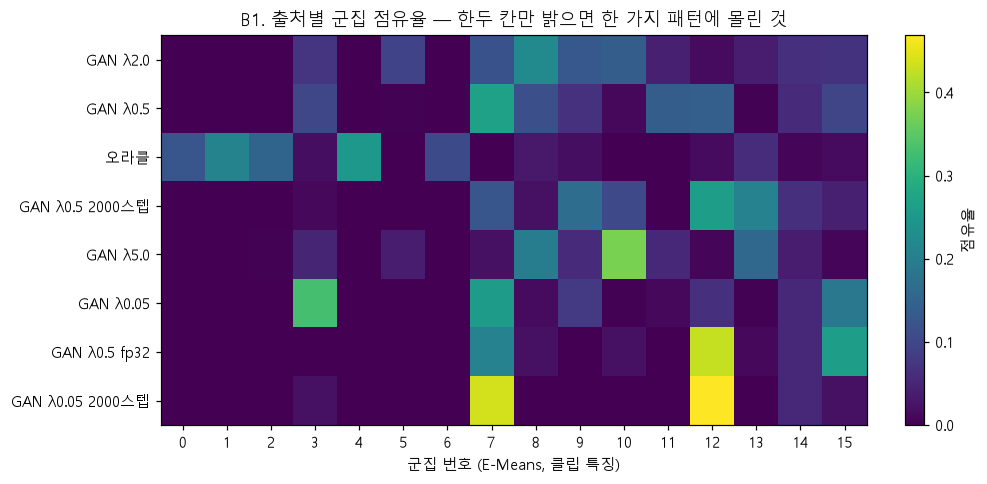

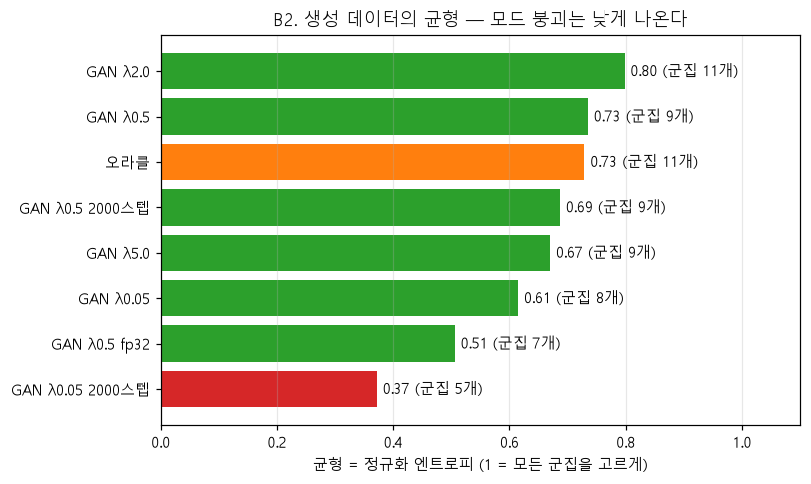

In [11]:
# 그래프 B1 (군집 점유 히트맵) · B2 (균형) — 같은 순서
order = list(tab.sort_values('균형(엔트로피)', ascending=False).index)     # 위 = 가장 고르게
fig, ax = plt.subplots(figsize=(9, 4.6))
im = ax.imshow(occ.loc[order].values, aspect='auto', cmap='viridis')
ax.set_yticks(range(len(order)), order); ax.set_xticks(range(KC)); ax.set_xlabel('군집 번호 (E-Means, 클립 특징)')
ax.set_title('B1. 출처별 군집 점유율 — 한두 칸만 밝으면 한 가지 패턴에 몰린 것')
fig.colorbar(im, ax=ax, fraction=.03, label='점유율')
save(fig, 'B1_coverage_heatmap'); plt.show()
fig, ax = plt.subplots(figsize=(7.5, 4.6))
vals = tab.loc[order, '균형(엔트로피)'].values
cols = ['C1' if g == '오라클' else ('C3' if ('2000' in g and '0.05' in g) else 'C2') for g in order]
ax.barh(range(len(order)), vals, color=cols); ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
for k, (v, cov) in enumerate(zip(vals, tab.loc[order, '커버리지(군집 수)'])):
    ax.text(v + .01, k, f'{v:.2f} (군집 {cov}개)', va='center')
ax.set_xlim(0, 1.1); ax.set_xlabel('균형 = 정규화 엔트로피 (1 = 모든 군집을 고르게)'); ax.grid(alpha=.3, axis='x')
ax.set_title('B2. 생성 데이터의 균형 — 모드 붕괴는 낮게 나온다')
save(fig, 'B2_balance'); plt.show()

## 6. 실험 C — LUMI 적용 ②: 깜빡임 패치 군집 → ROI 후보
패치 군집 중 **위험 패치(판정기의 hazard_mask)가 몰리는 군집**이 있다면, 군집 번호만으로 위험 영역 후보를 고를 수 있다.
판정기 없이 '깜빡임 지문'만으로 위험 영역을 얼마나 골라내는지(정밀도·재현율)를 본다. 정답은 판정기 라벨이다.

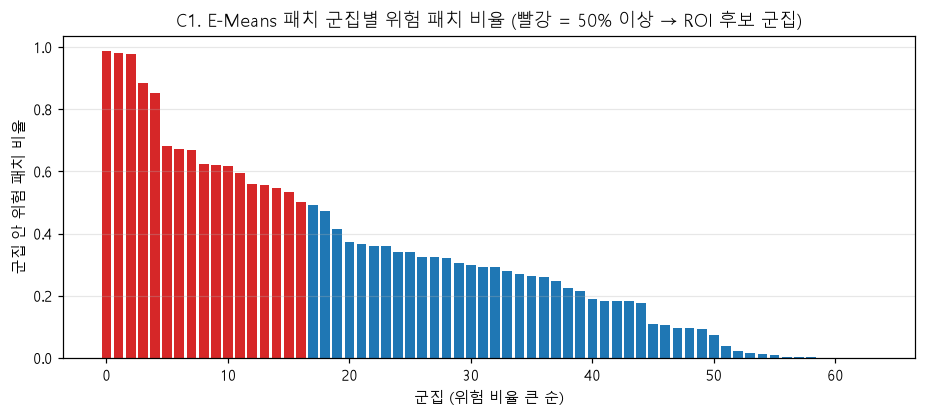

,군집 위험 비율 문턱,선택 군집 수,정밀도,재현율
0,0.3,30,0.585,0.826
1,0.5,17,0.736,0.607
2,0.7,5,0.942,0.315
3,0.9,3,0.981,0.214


In [12]:
Cn, _ = final_C[('E-Means', SEEDS[0])]
_, lab_all = test_mse(Cn, X)
hz = pm['hazard']
frac = pd.Series(hz).groupby(lab_all).mean().reindex(range(K), fill_value=0)
rows = []
for th in [0.3, 0.5, 0.7, 0.9]:
    sel = frac.index[frac >= th]; pred = np.isin(lab_all, sel)
    tp = (pred & hz).sum()
    rows.append({'군집 위험 비율 문턱': th, '선택 군집 수': len(sel),
                 '정밀도': tp / max(1, pred.sum()), '재현율': tp / max(1, hz.sum())})
roi = pd.DataFrame(rows).round(3); roi.to_csv(OUT / 'C_roi.csv', index=False, encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(10, 3.8))
o = frac.sort_values(ascending=False).index
ax.bar(range(K), frac[o], color=['C3' if v >= .5 else 'C0' for v in frac[o]])
ax.set_xlabel('군집 (위험 비율 큰 순)'); ax.set_ylabel('군집 안 위험 패치 비율'); ax.grid(alpha=.3, axis='y')
ax.set_title('C1. E-Means 패치 군집별 위험 패치 비율 (빨강 = 50% 이상 → ROI 후보 군집)')
save(fig, 'C1_roi_clusters'); plt.show(); roi

## 7. 결론 기록 (실행 후 직접 채우기)
| 질문 | 근거 그래프·표 | 답 |
|---|---|---|
| E-Means 가 적은 epoch 로 Lloyd 품질에 도달하는가? | A1, A3 | |
| 시간 대비로도 이득인가? (우리 규모, CPU) | A2, A3 | |
| 단순 EMA(우리 착안)는 어디서 E-Means 와 갈리는가? | A1, A6 | |
| 결과가 시드에 흔들리지 않는가? | A1 오차막대, A5 | |
| 오라클과 GAN 중 어느 쪽이 더 고르게 퍼져 있는가? λ_div 효과는? | B1, B2 | |
| 깜빡임 지문 군집만으로 위험 영역 후보를 고를 수 있는가? | C1, 표 | |

**해석 주의**
- 시험 MSE 가 좋아지는 것은 '군집이 데이터를 잘 요약한다'는 뜻이지, PSE 탐지가 좋아진다는 뜻이 아니다. 탐지 개선은 E1~E4 실험(PLAN)으로 따로 보여야 한다.
- 여기서 '위험' 정답은 우리 판정기 라벨이다(label bias 그대로). 실제 영상(South·Kaya) 특징을 같은 공간에 넣어 비교하는 것이 다음 단계다.
- 논문의 속도 주장(GPU, 수억 개 임베딩)은 이 규모(232만 개, 26차원, CPU)와 조건이 다르다. Lloyd 는 C++(faiss), E-Means·단순 EMA 는 파이썬 루프라 시간 비교는 구현 차이도 섞여 있다.


## 8. 검증 보강 — '처음부터 낮다'는 의문에 대한 답 (2026-11-12)
위 그래프 A1 에서 E-Means 가 1 epoch 부터 낮아 보인 이유와, 차이가 우연인지를 확인한다.
- **1 epoch 의 의미가 다르다**: Lloyd 는 1 epoch = 중심 갱신 1번, E-Means 는 약 113번(배치 16,384), 단순 EMA 는 454번(배치 4,096).
  → R1: 가로축을 '본 데이터 양'으로 바꾸고 0 epoch(초기값)부터 그리면, E-Means 는 첫 epoch 안에서 수렴하는 과정이 보인다.
- **시드 10개 짝비교**(같은 초기값) → R2: 차이가 시드마다 같은 방향인지, 95% 신뢰구간과 Wilcoxon 부호순위 검정.
- 다시 계산: `python scripts/emeans_rigor.py --seeds 10` (약 11분, CPU). 이 셀은 저장된 결과만 읽는다.

 (같은 초기값, 시드 10)

| 비교                              |   n |   평균 차이(%) | 95% CI         | 음수인 시드   |   Wilcoxon p |
|:----------------------------------|----:|---------------:|:---------------|:--------------|-------------:|
| E-Means 1 epoch 대 Lloyd 25 epoch |  10 |          -1.35 | [-1.67, -1.02] | 10/10         |        0.002 |
| E-Means 25 대 Lloyd 25            |  10 |          -3.82 | [-4.74, -2.90] | 10/10         |        0.002 |
| 단순 EMA 25 대 Lloyd 25           |  10 |          -5    | [-6.34, -3.65] | 10/10         |        0.002 |
| 단순 EMA 25 대 E-Means 25         |  10 |          -1.23 | [-1.78, -0.68] | 10/10         |        0.002 |
| 단순 EMA 2 대 Lloyd 25            |  10 |          -1.91 | [-2.43, -1.38] | 10/10         |        0.002 |



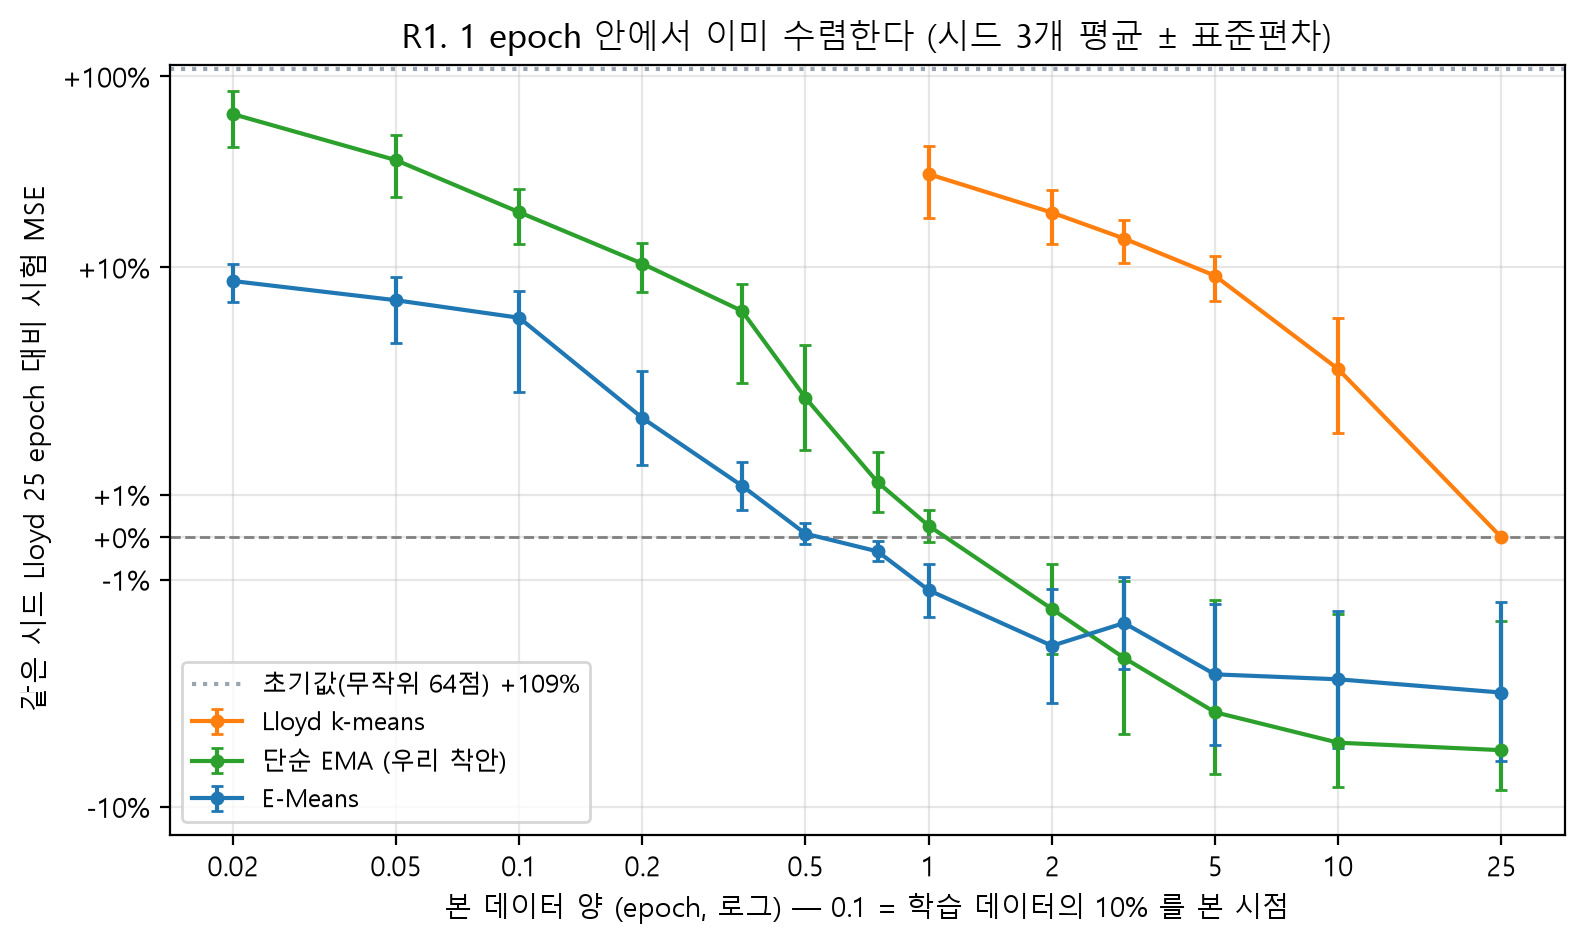

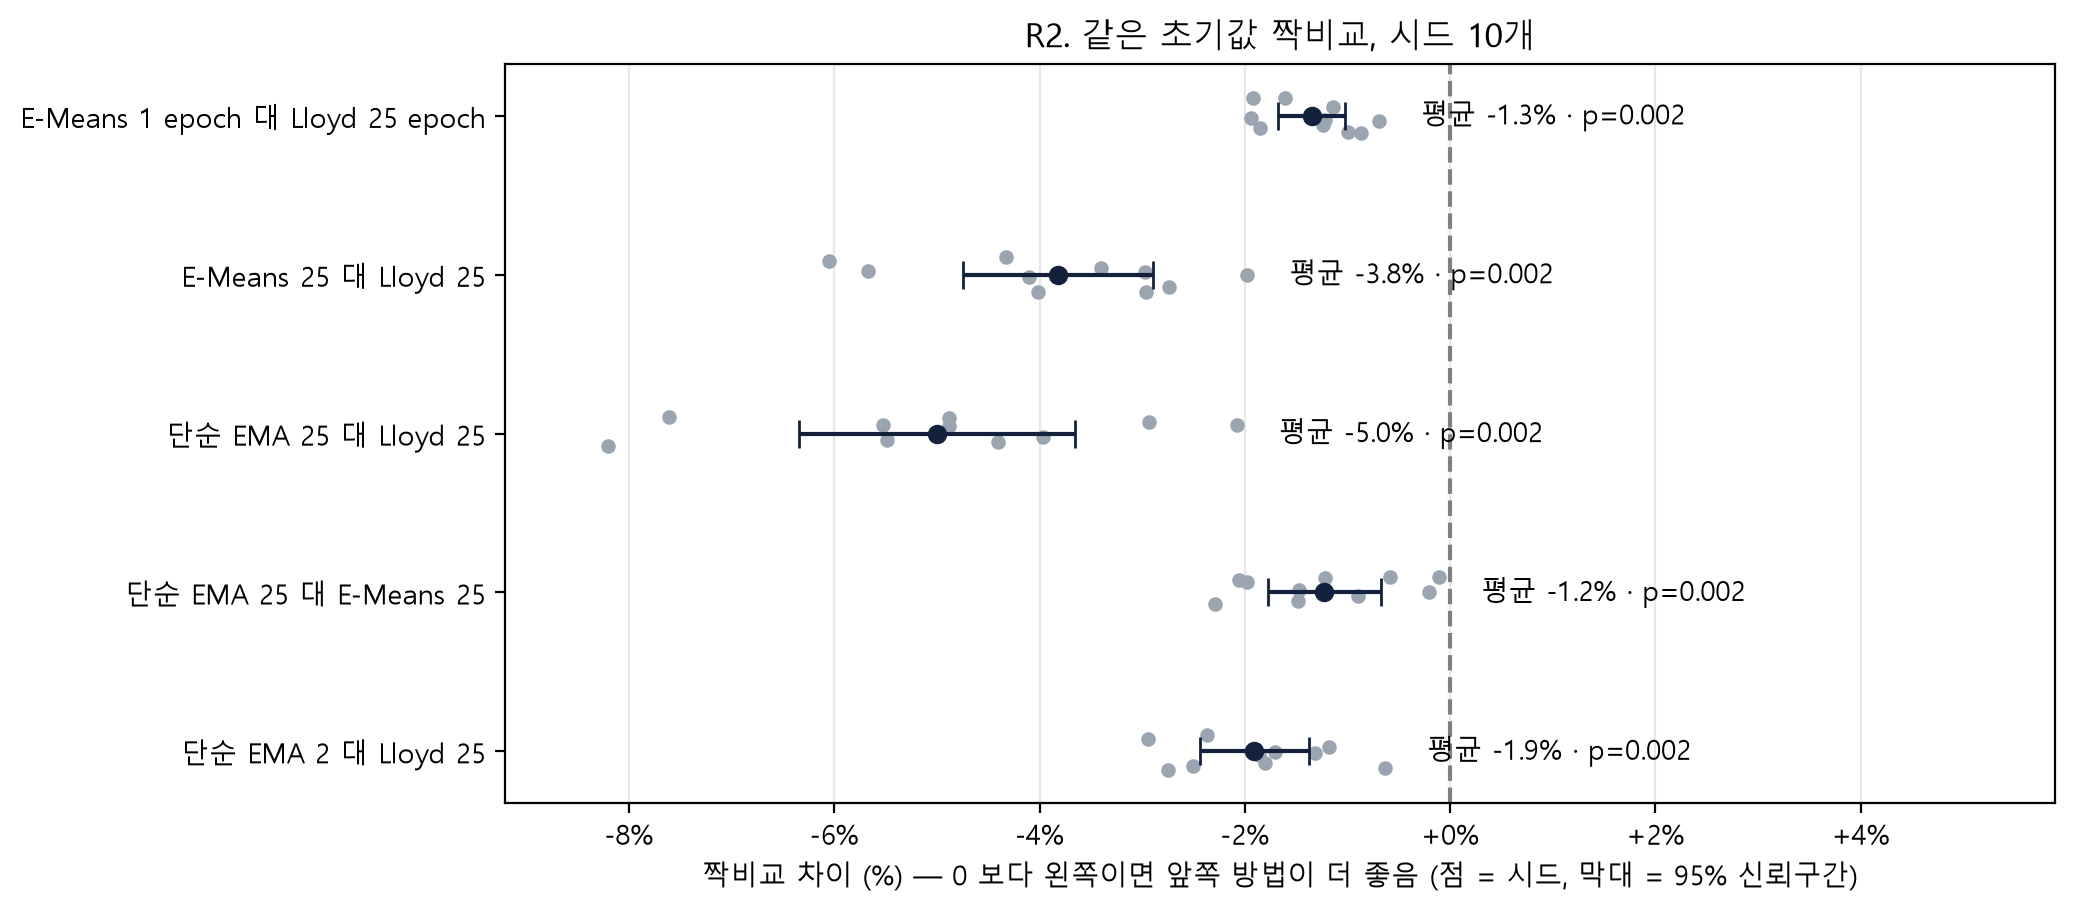

In [ ]:
# 검증 보강 결과 읽기 (계산은 scripts/emeans_rigor.py)
from IPython.display import Image, Markdown, display
display(Markdown((OUT / 'RIGOR.md').read_text(encoding='utf-8').split('## 짝비교')[1].split('![R2]')[0]))
display(Image(str(OUT / 'R1_data_seen.png'))); display(Image(str(OUT / 'R2_paired.png')))

**결론 (시드 10개)**
| 비교 | 평균 차이 | 95% CI | 같은 방향 시드 | p |
|---|---|---|---|---|
| E-Means 1 epoch 대 Lloyd 25 epoch | −1.35% | [−1.67, −1.02] | 10/10 | 0.002 |
| 단순 EMA 25 대 E-Means 25 | −1.23% | [−1.78, −0.68] | 10/10 | 0.002 |
| 단순 EMA 25 대 Lloyd 25 | −5.00% | [−6.34, −3.65] | 10/10 | 0.002 |
- E-Means 는 '처음부터 낮은' 것이 아니라 **0.5 epoch(데이터 절반)를 본 시점에 Lloyd 25 epoch 수준**에 도달한다(R1).
- 이 데이터에서는 차이가 작지만(1~5%) **모든 시드에서 같은 방향**이라 우연이 아니다.
- 한계: 데이터 하나(LUMI 패치 26차원), K = 64, CPU. 다른 데이터·K 로의 일반화는 아직 검증하지 않았다.